# CSE4132 – Artificial Intelligence Lab | Set A
**University of Rajshahi – Dept. of CSE | B.Sc. Engg. Part-IV Odd Semester Examination 2024**

| Problem | Task | Marks |
|---|---|---|
| 1 | Deep Neural Network (DNN) regression for y = 5x⁴ − 10x³ − x + 5 | 6.0 |
| 2 | VGG16-based classifier: airplane / automobile / truck (CIFAR-10) with fine-tuning | 7.0 |

**How to run:** Open in **Google Colab** → `Runtime > Change runtime type > GPU (T4)` → `Runtime > Run all`.
Problem 1 runs in about a minute even on CPU. Problem 2 needs a GPU and internet (CIFAR-10 and the ImageNet VGG16 weights are downloaded automatically by Keras).

---
# Problem 1 – DNN for the polynomial y = 5x⁴ − 10x³ − x + 5

**Plan**
1. Generate samples with x uniformly in [−20, +20] and compute y.
2. Split: 80 % train / 10 % validation / 10 % test.
3. Normalize x and y to [−1, +1] using **Min-Max scaling fitted on the training set only** (avoids data leakage).
4. Build a DNN with hidden layers of 32, 64 and 128 neurons and show the summary (parameter count).
5. Train with early stopping and learning-rate reduction.
6. Predict on the test set, convert back to the original scale, and report accuracy (R², MAE, RMSE) and plots of predicted vs. true values.

In [3]:
# ---------- 1.0 Imports and reproducibility ----------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


In [4]:
# ---------- 1.1 Generate the training data ----------
def polynomial(x):
    # Target function: y = 5x^4 - 10x^3 - x + 5
    return 5 * x**4 - 10 * x**3 - x + 5

N_SAMPLES = 20000                                   # total number of samples
x = np.random.uniform(-20, 20, size=(N_SAMPLES, 1)) # x in [-20, +20]
y = polynomial(x)                                   # true y values

print("x range:", x.min().round(3), "to", x.max().round(3))
print("y range:", y.min().round(1), "to", y.max().round(1))

x range: -20.0 to 19.997
y range: -4.9 to 879945.0


In [5]:
# ---------- 1.2 Split: 10 % test, 10 % validation, 80 % training ----------
# Step 1: take out 10 % of ALL data as the test set.
x_trainval, x_test, y_trainval, y_test = train_test_split(
    x, y, test_size=0.10, random_state=SEED)

# Step 2: 10 % of the ORIGINAL data = 1/9 of the remaining 90 %  -> validation set.
x_train, x_val, y_train, y_val = train_test_split(
    x_trainval, y_trainval, test_size=1/9, random_state=SEED)

print(f"Train: {len(x_train)} | Validation: {len(x_val)} | Test: {len(x_test)}")

Train: 16000 | Validation: 2000 | Test: 2000


In [6]:
# ---------- 1.3 Normalize data to the range [-1, +1] ----------
# Min-Max scaling:  x_scaled = 2 * (x - x_min) / (x_max - x_min) - 1
# The scalers are FITTED ON TRAINING DATA ONLY and then applied to val/test data.
x_scaler = MinMaxScaler(feature_range=(-1, 1))
y_scaler = MinMaxScaler(feature_range=(-1, 1))

x_train_s = x_scaler.fit_transform(x_train)
y_train_s = y_scaler.fit_transform(y_train)

x_val_s,  y_val_s  = x_scaler.transform(x_val),  y_scaler.transform(y_val)
x_test_s, y_test_s = x_scaler.transform(x_test), y_scaler.transform(y_test)

print("Scaled x_train range:", x_train_s.min().round(3), x_train_s.max().round(3))
print("Scaled y_train range:", y_train_s.min().round(3), y_train_s.max().round(3))

Scaled x_train range: -1.0 1.0
Scaled y_train range: -1.0 1.0


In [7]:
# ---------- 1.4 Build the DNN (hidden layers: 32 -> 64 -> 128) ----------
model = keras.Sequential([
    keras.Input(shape=(1,)),                  # one input feature: x
    layers.Dense(32,  activation="relu"),     # hidden layer 1
    layers.Dense(64,  activation="relu"),     # hidden layer 2
    layers.Dense(128, activation="relu"),     # hidden layer 3
    layers.Dense(1,   activation="linear"),   # output layer: y (regression -> linear)
], name="Polynomial_DNN")

# Display the generated DNN with the number of parameters.
model.summary()

# Hand check of parameters = (inputs x neurons) + biases
#   Dense(32) : 1*32   + 32  =    64
#   Dense(64) : 32*64  + 64  =  2,112
#   Dense(128): 64*128 + 128 =  8,320
#   Dense(1)  : 128*1  + 1   =    129
#   TOTAL                    = 10,625
print("Total parameters:", model.count_params())

I0000 00:00:1792860049.795908      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792860049.801038      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "Polynomial_DNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,625 (41.50 KB)

 Trainable params: 10,625 (41.50 KB)

 Non-trainable params: 0 (0.00 B)

Total parameters: 10625


In [8]:
# ---------- 1.5 Compile and train ----------
model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
              loss="mse",
              metrics=["mae"])

callbacks = [
    # Stop when validation loss stops improving and keep the best weights.
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=20,
                                  restore_best_weights=True, verbose=1),
    # Halve the learning rate if validation loss plateaus.
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                      patience=7, min_lr=1e-6, verbose=1),
]

history = model.fit(x_train_s, y_train_s,
                    validation_data=(x_val_s, y_val_s),
                    epochs=200,            # upper limit; early stopping will cut it short
                    batch_size=128,
                    callbacks=callbacks,
                    verbose=2)

Epoch 1/200


I0000 00:00:1792860054.090379     139 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


125/125 - 3s - 25ms/step - loss: 0.1632 - mae: 0.2857 - val_loss: 0.0089 - val_mae: 0.0600 - learning_rate: 0.0010
Epoch 2/200
125/125 - 0s - 3ms/step - loss: 0.0024 - mae: 0.0284 - val_loss: 6.9174e-04 - val_mae: 0.0145 - learning_rate: 0.0010
Epoch 3/200
125/125 - 0s - 3ms/step - loss: 3.3389e-04 - mae: 0.0104 - val_loss: 2.0250e-04 - val_mae: 0.0075 - learning_rate: 0.0010
Epoch 4/200
125/125 - 0s - 3ms/step - loss: 1.3812e-04 - mae: 0.0072 - val_loss: 8.7977e-05 - val_mae: 0.0052 - learning_rate: 0.0010
Epoch 5/200
125/125 - 0s - 3ms/step - loss: 7.1655e-05 - mae: 0.0053 - val_loss: 4.7639e-05 - val_mae: 0.0041 - learning_rate: 0.0010
Epoch 6/200
125/125 - 0s - 3ms/step - loss: 4.8315e-05 - mae: 0.0046 - val_loss: 3.3887e-05 - val_mae: 0.0041 - learning_rate: 0.0010
Epoch 7/200
125/125 - 0s - 3ms/step - loss: 2.6206e-05 - mae: 0.0033 - val_loss: 2.8122e-05 - val_mae: 0.0042 - learning_rate: 0.0010
Epoch 8/200
125/125 - 0s - 3ms/step - loss: 2.3561e-05 - mae: 0.0032 - val_loss: 1.78

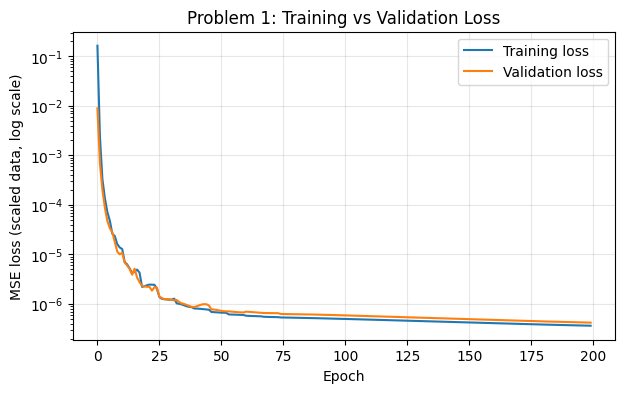

In [9]:
# ---------- 1.6 Training / validation loss curves ----------
plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.yscale("log")
plt.xlabel("Epoch"); plt.ylabel("MSE loss (scaled data, log scale)")
plt.title("Problem 1: Training vs Validation Loss")
plt.legend(); plt.grid(alpha=0.3); plt.show()

In [10]:
# ---------- 1.7 Predict on the test data and evaluate ----------
y_pred_s = model.predict(x_test_s, verbose=0)         # prediction in scaled space
y_pred   = y_scaler.inverse_transform(y_pred_s)       # back to the ORIGINAL y scale

r2   = r2_score(y_test, y_pred)
mae  = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
rel_rmse = rmse / (y_test.max() - y_test.min()) * 100  # RMSE as % of the y range

print(f"R^2 score (prediction accuracy) : {r2:.6f}  ({r2*100:.3f} %)")
print(f"MAE                             : {mae:,.2f}")
print(f"RMSE                            : {rmse:,.2f}")
print(f"RMSE as % of y-range            : {rel_rmse:.4f} %")

# Table: first 10 test samples, true vs predicted
comparison = pd.DataFrame({"x": x_test.ravel(),
                           "True y": y_test.ravel(),
                           "Predicted y": y_pred.ravel()})
comparison["Abs. error"] = (comparison["True y"] - comparison["Predicted y"]).abs()
display(comparison.head(10).round(2))

R^2 score (prediction accuracy) : 0.999999  (100.000 %)
MAE                             : 154.82
RMSE                            : 258.77
RMSE as % of y-range            : 0.0297 %


,x,True y,Predicted y,Abs. error
0,17.47,412164.90,412217.250000,52.35
1,2.45,35.52,134.279999,98.76
2,-9.91,57995.58,58137.480469,141.90
3,3.72,442.53,572.250000,129.73
4,4.74,1464.91,1250.420044,214.49
5,-12.15,126970.68,126952.023438,18.66
6,-5.27,5328.65,5637.759766,309.11
7,-9.98,59585.67,59741.078125,155.41
8,17.08,375466.66,375351.968750,114.69
9,-8.78,36518.57,36671.839844,153.27


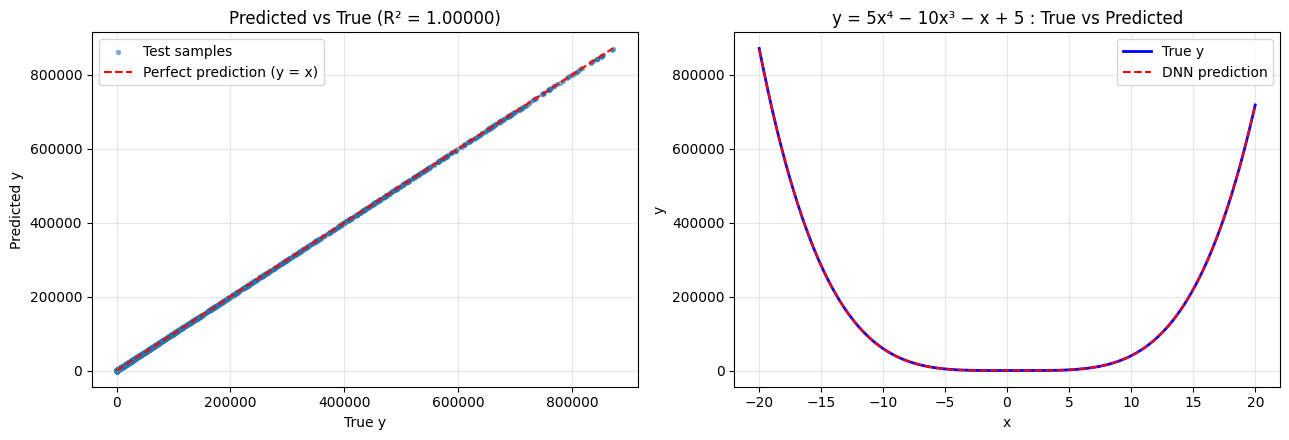

In [11]:
# ---------- 1.8 Prediction accuracy versus the true values of the test data ----------
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# (a) Predicted vs True: points on the red diagonal mean perfect prediction
lims = [y_test.min(), y_test.max()]
ax[0].scatter(y_test, y_pred, s=8, alpha=0.5, label="Test samples")
ax[0].plot(lims, lims, "r--", label="Perfect prediction (y = x)")
ax[0].set_xlabel("True y"); ax[0].set_ylabel("Predicted y")
ax[0].set_title(f"Predicted vs True (R² = {r2:.5f})")
ax[0].legend(); ax[0].grid(alpha=0.3)

# (b) The polynomial curve: true vs predicted over x (sorted for a clean line)
order = np.argsort(x_test.ravel())
ax[1].plot(x_test[order], y_test[order],  "b-",  lw=2, label="True y")
ax[1].plot(x_test[order], y_pred[order],  "r--", lw=1.5, label="DNN prediction")
ax[1].set_xlabel("x"); ax[1].set_ylabel("y")
ax[1].set_title("y = 5x⁴ − 10x³ − x + 5 : True vs Predicted")
ax[1].legend(); ax[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

**Problem 1 – Notes for the viva**
- **Why normalize?** y reaches about 880,000 while x lies in [−20, 20]. Such large, unbalanced values give huge gradients and unstable training, so both are scaled to [−1, 1].
- **Why fit the scaler on training data only?** Fitting on all data lets test-set information leak into training.
- **Why a linear output layer?** This is regression, so the output must be unbounded (no sigmoid/softmax); MSE is the loss.
- **Why ReLU hidden layers?** They are non-linear, so the network can approximate the quartic curve; they also avoid vanishing gradients.
- **Accuracy for regression** is not "percent correct". It is measured with R², MAE and RMSE. R² close to 1 means a very good fit.
- **Early stopping + ReduceLROnPlateau** pick an appropriate number of epochs automatically and prevent overfitting.

**Problem 2 – Notes for the viva**
- **Why VGG16 on 32×32 images?** The VGG16 conv base accepts any input of at least 32×32. After 5 max-pooling layers a 32×32 image becomes 1×1×512 features.
- **Why a different preprocessing?** `preprocess_input` applies the same ImageNet normalization that VGG16 was trained with, which is required for the pretrained weights to work properly.
- **Transfer learning:** the early layers learn generic features (edges, textures), the later layers learn task-specific features. So early blocks are frozen and only later blocks are adapted.
- **Why a small learning rate in full fine-tuning?** Large updates would destroy the pretrained weights (catastrophic forgetting).
- **Callbacks:** `EarlyStopping` stops training when val_loss stops improving and restores the best weights; `ReduceLROnPlateau` multiplies the learning rate by 0.2 when val_loss plateaus.
- **Expected result:** both fine-tuned models normally beat the frozen baseline. Typical test accuracy is roughly 90–95 %; the exact numbers vary with hardware and random seeds. Full fine-tuning gives the best accuracy but is slowest and most prone to overfitting. Partial fine-tuning is a good accuracy/cost trade-off.